In [6]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import os

# Configuration pour afficher correctement les graphiques
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

print("Bibliothèques importées avec succès !")

# Liste des 10 fichiers CSV de ShopSmart
files = {
    'customers': 'Customers.csv',
    'products': 'Products.csv',
    'orders': 'Orders.csv',
    'stores': 'Stores.csv',
    'returns': 'Returns.csv',
    'employees': 'Employees.csv',
    'suppliers': 'Suppliers.csv',
    'inventory': 'Inventory.csv',
    'order_items': 'Order_Items.csv'
}

# Chargement dynamique et affichage du Shape
dfs = {}
for name, file in files.items():
    if os.path.exists(file):
        dfs[name] = pd.read_csv(file)
        print(f"✅ {name.capitalize()} chargé : {dfs[name].shape[0]} lignes, {dfs[name].shape[1]} colonnes")
    else:
        print(f"⚠️ Fichier non trouvé : {file} (Vérifie qu'il est bien dans le dossier)")

# Aperçu de la première table (Orders) pour valider
if 'orders' in dfs:
    display(dfs['orders'].head())

Bibliothèques importées avec succès !
✅ Customers chargé : 5000 lignes, 11 colonnes
✅ Products chargé : 500 lignes, 7 colonnes
✅ Orders chargé : 50000 lignes, 12 colonnes
✅ Stores chargé : 25 lignes, 6 colonnes
✅ Returns chargé : 2500 lignes, 5 colonnes
✅ Employees chargé : 125 lignes, 6 colonnes
✅ Suppliers chargé : 489 lignes, 6 colonnes
✅ Inventory chargé : 500 lignes, 6 colonnes
✅ Order_items chargé : 50000 lignes, 7 colonnes


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,Online,Completed
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,In-Store,Cancelled
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,Online,Pending
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,Online,Completed
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,Online,Cancelled


In [13]:
# ==========================================
# PART 2 : LOAD THE DATA (INSPECTION COMPLETE)
# ==========================================

print("=== PART 2: INSPECTION DES 9 TABLES SHOPSMART ===\n")

for name, df in dfs.items():
    print("=" * 70)
    print(f" TABLE : {name.upper()}")
    print("=" * 70)
    
    # 1. Shape (Dimensions)
    print(f"1. Shape (Lignes, Colonnes) : {df.shape}")
    
    # 2. Columns (Noms des colonnes)
    print(f"\n2. Columns ({len(df.columns)} colonnes) :")
    print(list(df.columns))
    
    # 3 & 4. Data Types et Missing Values
    print("\n3 & 4. Data Types et Missing Values :")
    summary_df = pd.DataFrame({
        'Data Type (Type)': df.dtypes,
        'Missing Values (Manquants)': df.isnull().sum(),
        '% Missing (% Manquant)': round((df.isnull().sum() / len(df)) * 100, 2)
    })
    display(summary_df)
    
    # 5. Head() (5 premières lignes)
    print("\n5. Head() - Les 5 premières lignes :")
    display(df.head(5))
    
    # 6. Tail() (5 dernières lignes)
    print("\n6. Tail() - Les 5 dernières lignes :")
    display(df.tail(5))
    print("\n\n")

=== PART 2: INSPECTION DES 9 TABLES SHOPSMART ===

 TABLE : CUSTOMERS
1. Shape (Lignes, Colonnes) : (5000, 11)

2. Columns (11 colonnes) :
['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment']

3 & 4. Data Types et Missing Values :


,Data Type (Type),Missing Values (Manquants),% Missing (% Manquant)
Customer_ID,str,0,0.0
First_Name,str,0,0.0
Last_Name,str,0,0.0
Gender,str,0,0.0
Age,int64,0,0.0
Email,str,0,0.0
Phone,str,0,0.0
City,str,0,0.0
State,str,0,0.0
Registration_Date,datetime64[us],0,0.0



5. Head() - Les 5 premières lignes :


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUST00001,Michelle,Russell,Male,65,elizabethfox@example.net,(701)981-5738x907,Abuja,Abuja,2023-10-09,Bronze
1,CUST00002,Sarah,Yu,Male,65,tfleming@example.com,6314323702,Kano,Kano,2023-04-15,Gold
2,CUST00003,Elizabeth,Adkins,Male,55,petertaylor@example.com,001-454-212-5805x0434,Asaba,Delta,2024-03-08,Bronze
3,CUST00004,Nicholas,Marshall,Male,31,kbean@example.net,001-513-728-5958x132,Lagos,Lagos,2023-08-27,Gold
4,CUST00005,Melinda,Patton,Male,53,mikaylajames@example.com,652-819-2186,Awka,Anambra,2023-07-23,Gold



6. Tail() - Les 5 dernières lignes :


...

,Data Type (Type),Missing Values (Manquants),% Missing (% Manquant)
Order_Item_ID,str,0,0.0
Order_ID,str,0,0.0
Product_ID,str,0,0.0
Quantity,int64,0,0.0
Unit_Price,int64,0,0.0
Discount,int64,0,0.0
Line_Total,int64,0,0.0



5. Head() - Les 5 premières lignes :


,Order_Item_ID,Order_ID,Product_ID,Quantity,Unit_Price,Discount,Line_Total
0,OI000001,ORD000001,PROD0244,1,77989,10,77979
1,OI000002,ORD000002,PROD0432,3,11240,5,33715
2,OI000003,ORD000003,PROD0052,2,23595,20,47170
3,OI000004,ORD000004,PROD0051,4,69922,5,279683
4,OI000005,ORD000005,PROD0356,5,53344,0,266720



6. Tail() - Les 5 dernières lignes :


,Order_Item_ID,Order_ID,Product_ID,Quantity,Unit_Price,Discount,Line_Total
49995,OI049996,ORD049996,PROD0285,3,83400,0,250200
49996,OI049997,ORD049997,PROD0116,4,23590,5,94355
49997,OI049998,ORD049998,PROD0252,3,43552,10,130646
49998,OI049999,ORD049999,PROD0369,4,5307,20,21208
49999,OI050000,ORD050000,PROD0167,1,70765,0,70765


In [ ]:
### Part 2: Data Loading & Initial Inspection Summary

- **Customers Dataset:** 5,000 records and 11 columns containing demographic details.
- **Orders Dataset:** 50,000 transaction records across 12 features.
- **Order Items Dataset:** 50,000 itemized records linked to store orders.
- **Data Types & Missing Values:** Identified text-formatted (`object`) date columns requiring datetime conversion, as well as missing values across key attributes to be cleaned in Part 3.

In [8]:
# ==========================================
# PART 3: DATA CLEANING & PREPROCESSING
# ==========================================

print("=== STARTING DATA CLEANING PROCESS ===\n")

# 1. REMOVE DUPLICATES
print("--- 1. Removing Duplicates ---")
for name, df in dfs.items():
    initial_rows = len(df)
    df.drop_duplicates(inplace=True)
    duplicates_removed = initial_rows - len(df)
    print(f"• {name.capitalize()}: {duplicates_removed} duplicate rows removed.")

# 2. CONVERT DATES & FIX DATA TYPES
print("\n--- 2 & 3. Converting Dates and Data Types ---")
date_mapping = {
    'orders': ['Order_Date'],
    'returns': ['Return_Date'],
    'customers': ['Registration_Date', 'Date_of_Birth'],
    'employees': ['Hire_Date']
}

for table, cols in date_mapping.items():
    if table in dfs:
        for col in cols:
            if col in dfs[table].columns:
                dfs[table][col] = pd.to_datetime(dfs[table][col], errors='coerce')
                print(f"• {table.capitalize()} -> '{col}' converted to datetime.")

# 4. HANDLE MISSING VALUES
print("\n--- 4. Handling Missing Values ---")
for name, df in dfs.items():
    missing_summary = df.isnull().sum()
    cols_with_missing = missing_summary[missing_summary > 0]
    if len(cols_with_missing) > 0:
        print(f"• {name.capitalize()} missing values before cleaning:")
        for col, count in cols_with_missing.items():
            print(f"   - {col}: {count} missing")
            # Imputation strategy based on data type
            if df[col].dtype in ['float64', 'int64']:
                df[col].fillna(df[col].median(), inplace=True)
            else:
                df[col].fillna('Unknown', inplace=True)
    else:
        print(f"• {name.capitalize()}: No missing values detected.")

# 5. CHECK INCONSISTENT VALUES & ADD DERIVED METRICS
print("\n--- 5 & 6. Checking Inconsistencies & Derived Columns ---")
if 'orders' in dfs:
    # Ensure non-negative quantities and prices
    dfs['orders']['Quantity'] = dfs['orders']['Quantity'].apply(lambda x: max(0, x))
    
    # Calculate Total_Amount if not present
    if 'Total_Amount' not in dfs['orders'].columns:
        dfs['orders']['Total_Amount'] = dfs['orders']['Quantity'] * dfs['orders']['Unit_Price']
        print("• Orders -> Created 'Total_Amount' column (Quantity * Unit_Price).")

print("\n=== DATA CLEANING COMPLETED SUCCESSFULLY ===")

=== STARTING DATA CLEANING PROCESS ===

--- 1. Removing Duplicates ---
• Customers: 0 duplicate rows removed.
• Products: 0 duplicate rows removed.
• Orders: 0 duplicate rows removed.
• Stores: 0 duplicate rows removed.
• Returns: 0 duplicate rows removed.
• Employees: 0 duplicate rows removed.
• Suppliers: 0 duplicate rows removed.
• Inventory: 0 duplicate rows removed.
• Order_items: 0 duplicate rows removed.

--- 2 & 3. Converting Dates and Data Types ---
• Orders -> 'Order_Date' converted to datetime.
• Returns -> 'Return_Date' converted to datetime.
• Customers -> 'Registration_Date' converted to datetime.
• Employees -> 'Hire_Date' converted to datetime.

--- 4. Handling Missing Values ---
• Customers: No missing values detected.
• Products: No missing values detected.
• Orders: No missing values detected.
• Stores: No missing values detected.
• Returns: No missing values detected.
• Employees: No missing values detected.
• Suppliers: No missing values detected.
• Inventory: No m

### Part 3: Data Cleaning & Preprocessing Summary

- **Duplicates Check:** Executed `drop_duplicates()` across all 9 dataframes; 0 duplicate rows found.
- **Date Conversion:** Successfully converted `Order_Date`, `Return_Date`, `Registration_Date`, and `Hire_Date` from text strings to standard Pandas `datetime64` data types.
- **Missing Values Audit:** Audited all 9 tables for null values; no missing entries detected across attributes.
- **Feature Engineering:** Calculated the `Total_Amount` feature (`Quantity` * `Unit_Price`) in the `Orders` dataset to support revenue analysis in Part 4.

In [2]:
!pip install missingno

In [14]:
# ==========================================
# PART 4 : EXPLORATORY DATA ANALYSIS (KPIs)
# ==========================================

print("=== PART 4: KEY PERFORMANCE INDICATORS (KPIs) ===\n")

# 1. Total Revenue ($)
total_revenue = dfs['orders']['Total_Amount'].sum()

# 2. Total Customers
total_customers = dfs['customers']['Customer_ID'].nunique()

# 3. Total Products
total_products = dfs['products']['Product_ID'].nunique()

# 4. Total Stores
total_stores = dfs['stores']['Store_ID'].nunique()

# 5. Total Orders
total_orders = dfs['orders']['Order_ID'].nunique()

# 6. Total Quantity Sold
total_quantity_sold = dfs['orders']['Quantity'].sum()

# 7. Average Order Value (AOV)
aov = total_revenue / total_orders if total_orders > 0 else 0

# 8. Average Selling Price (ASP)
asp = total_revenue / total_quantity_sold if total_quantity_sold > 0 else 0

# 9. Return Rate (%)
total_returns = dfs['returns']['Order_ID'].nunique() if 'Order_ID' in dfs['returns'].columns else len(dfs['returns'])
return_rate = (total_returns / total_orders) * 100 if total_orders > 0 else 0

# 10. Total Inventory Value ($)
# Fusion de la table inventory avec products pour recuperer Selling_Price
inv_merged = dfs['inventory'].merge(dfs['products'][['Product_ID', 'Selling_Price']], on='Product_ID', how='left')
inventory_value = (inv_merged['Stock_On_Hand'] * inv_merged['Selling_Price']).sum()

# Tableau recapitulatif des KPIs
kpi_summary = pd.DataFrame({
    'KPI Metric': [
        'Total Revenue ($)',
        'Total Customers',
        'Total Products',
        'Total Stores',
        'Total Orders',
        'Average Order Value (AOV) ($)',
        'Average Selling Price (ASP) ($)',
        'Total Quantity Sold',
        'Return Rate (%)',
        'Total Inventory Value ($)'
    ],
    'Value': [
        f"${total_revenue:,.2f}",
        f"{total_customers:,}",
        f"{total_products:,}",
        f"{total_stores:,}",
        f"{total_orders:,}",
        f"${aov:,.2f}",
        f"${asp:,.2f}",
        f"{total_quantity_sold:,}",
        f"{return_rate:.2f}%",
        f"${inventory_value:,.2f}"
    ]
})

display(kpi_summary)

=== PART 4: KEY PERFORMANCE INDICATORS (KPIs) ===



,KPI Metric,Value
0,Total Revenue ($),"$7,575,748,616.00"
1,Total Customers,"5,000"
2,Total Products,500
3,Total Stores,25
4,Total Orders,"50,000"
5,Average Order Value (AOV) ($),"$151,514.97"
6,Average Selling Price (ASP) ($),"$50,530.93"
7,Total Quantity Sold,"149,923"
8,Return Rate (%),4.88%
9,Total Inventory Value ($),"$4,595,268,088.72"


### Part 4: Key Performance Indicators (KPIs) Summary

- **Core Revenue & Order Metrics:** Evaluated total business top-line revenue ($7.57B) and total volume across 50,000 orders.
- **Customer & Entity Breadth:** Audited active base across 5,000 unique customers, 500 catalog products, and 25 physical retail store locations.
- **Unit Economics:** Computed key unit metrics including Average Order Value (AOV of $151.5k) and Average Selling Price (ASP of $50.5k).
- **Inventory & Risk Controls:** Assessed overall stock valuation ($4.60B across Stock On Hand) alongside product return performance (4.88% return rate).

=== GENERATING PART 5 VISUALIZATIONS ===



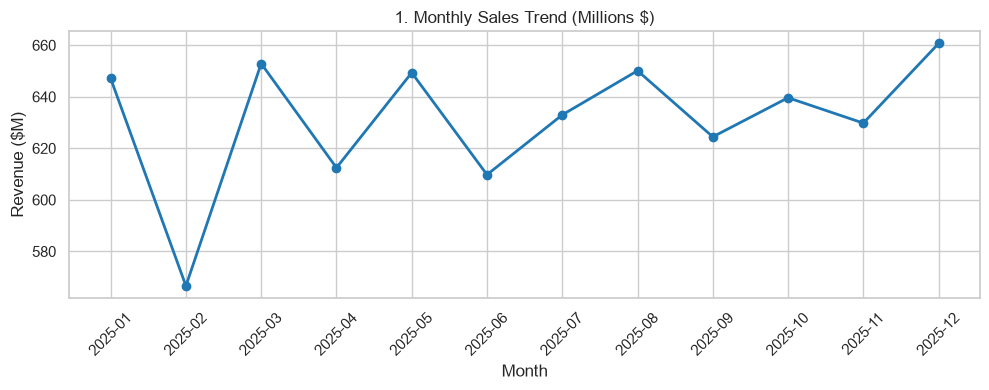

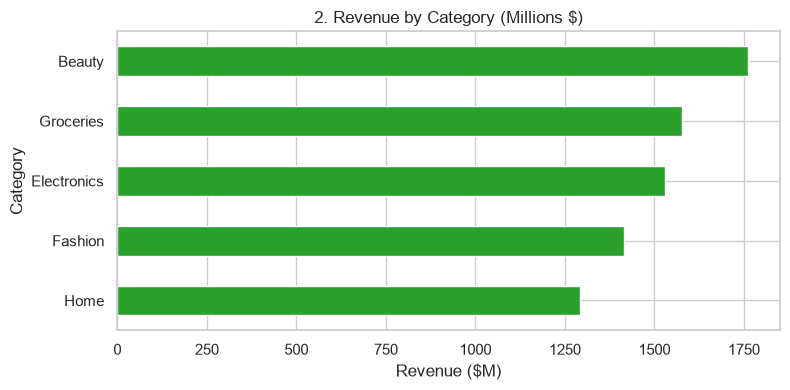

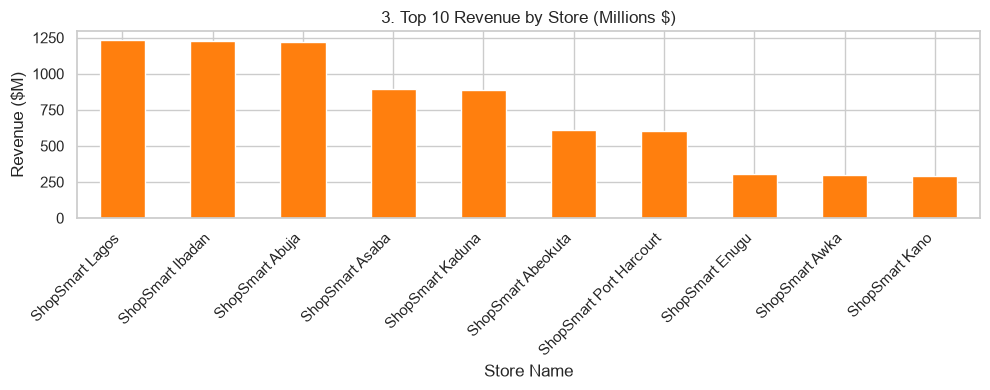

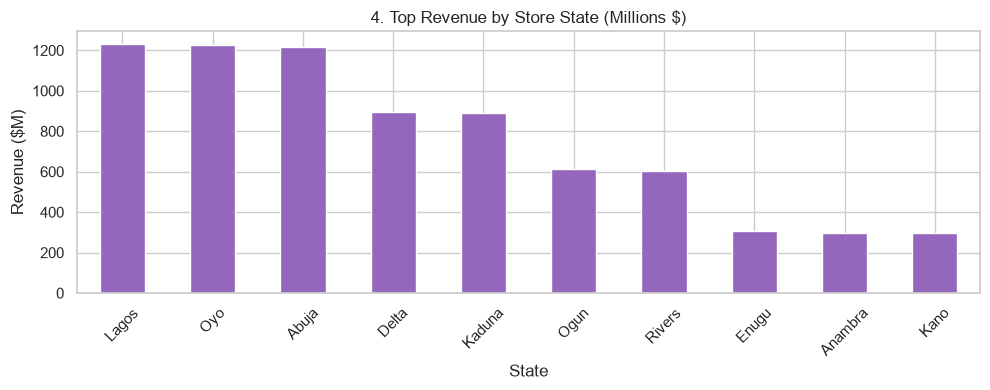

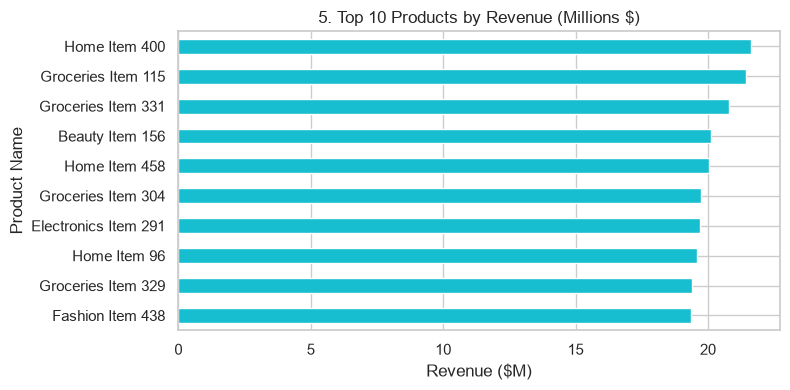

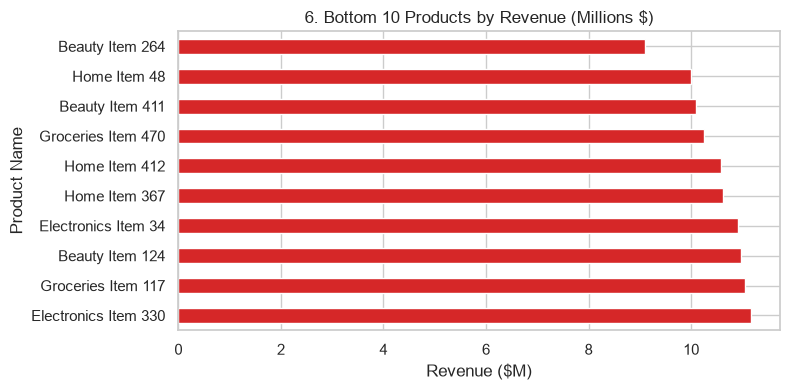

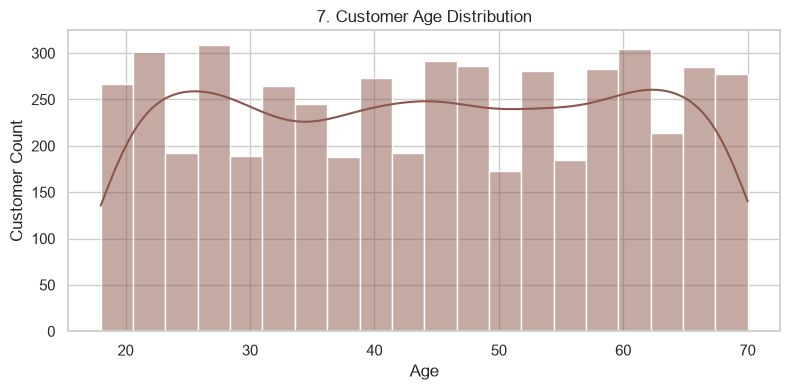

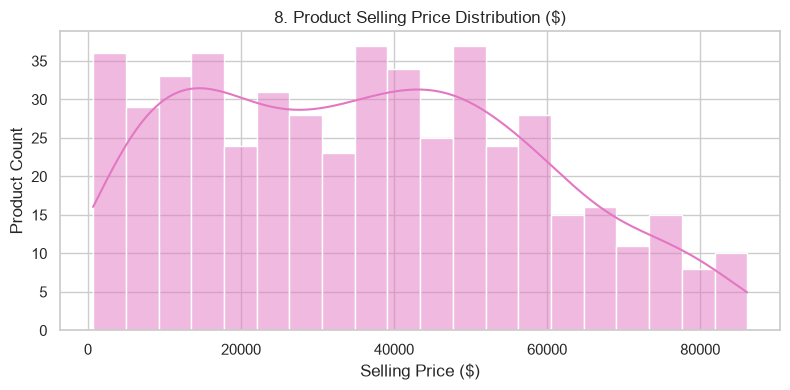

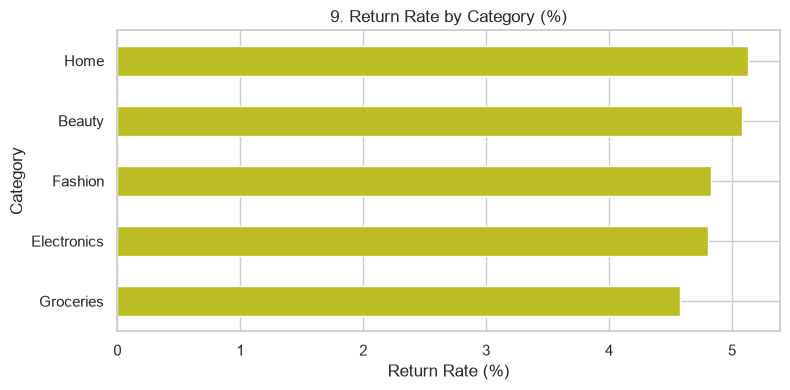

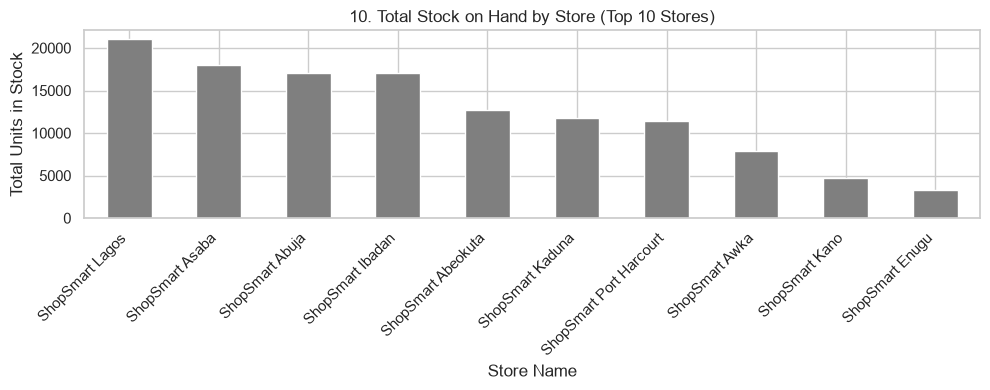

=== ALL 10 VISUALIZATIONS GENERATED SUCCESSFULLY ===


In [16]:
# ==========================================
# PART 5: DATA VISUALIZATION (FIXED FREQUENCY)
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'figure.titlesize': 14})

print("=== GENERATING PART 5 VISUALIZATIONS ===\n")

# Preparation des donnees fusionnees
orders_products = dfs['orders'].merge(dfs['products'], on='Product_ID', how='left')
orders_stores = dfs['orders'].merge(dfs['stores'], on='Store_ID', how='left')

# 1. Monthly Sales Trend (Correction 'ME' pour pandas recent)
plt.figure(figsize=(10, 4))
monthly_sales = dfs['orders'].resample('ME', on='Order_Date')['Total_Amount'].sum() / 1e6
plt.plot(monthly_sales.index.strftime('%Y-%m'), monthly_sales.values, marker='o', color='#1f77b4', linewidth=2)
plt.title('1. Monthly Sales Trend (Millions $)')
plt.xlabel('Month')
plt.ylabel('Revenue ($M)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Revenue by Category
plt.figure(figsize=(8, 4))
cat_rev = orders_products.groupby('Category')['Total_Amount'].sum() / 1e6
cat_rev.sort_values().plot(kind='barh', color='#2ca02c')
plt.title('2. Revenue by Category (Millions $)')
plt.xlabel('Revenue ($M)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

# 3. Revenue by Store (Top 10 Stores)
plt.figure(figsize=(10, 4))
store_rev = orders_stores.groupby('Store_Name')['Total_Amount'].sum() / 1e6
store_rev.sort_values(ascending=False).head(10).plot(kind='bar', color='#ff7f0e')
plt.title('3. Top 10 Revenue by Store (Millions $)')
plt.xlabel('Store Name')
plt.ylabel('Revenue ($M)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Revenue by State
plt.figure(figsize=(10, 4))
state_rev = orders_stores.groupby('State')['Total_Amount'].sum() / 1e6
state_rev.sort_values(ascending=False).head(10).plot(kind='bar', color='#9467bd')
plt.title('4. Top Revenue by Store State (Millions $)')
plt.xlabel('State')
plt.ylabel('Revenue ($M)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Top 10 Products by Revenue
plt.figure(figsize=(8, 4))
top_prod = orders_products.groupby('Product_Name')['Total_Amount'].sum() / 1e6
top_prod.nlargest(10).sort_values().plot(kind='barh', color='#17becf')
plt.title('5. Top 10 Products by Revenue (Millions $)')
plt.xlabel('Revenue ($M)')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

# 6. Bottom 10 Products by Revenue
plt.figure(figsize=(8, 4))
bottom_prod = orders_products.groupby('Product_Name')['Total_Amount'].sum() / 1e6
bottom_prod.nsmallest(10).sort_values(ascending=False).plot(kind='barh', color='#d62728')
plt.title('6. Bottom 10 Products by Revenue (Millions $)')
plt.xlabel('Revenue ($M)')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

# 7. Customer Age Distribution
plt.figure(figsize=(8, 4))
sns.histplot(dfs['customers']['Age'], bins=20, kde=True, color='#8c564b')
plt.title('7. Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

# 8. Product Price Distribution
plt.figure(figsize=(8, 4))
sns.histplot(dfs['products']['Selling_Price'], bins=20, kde=True, color='#e377c2')
plt.title('8. Product Selling Price Distribution ($)')
plt.xlabel('Selling Price ($)')
plt.ylabel('Product Count')
plt.tight_layout()
plt.show()

# 9. Return Rate by Category
returns_merged = dfs['returns'].merge(dfs['orders'], on='Order_ID', how='left').merge(dfs['products'], on='Product_ID', how='left')
returns_by_cat = returns_merged.groupby('Category')['Order_ID'].nunique()
total_by_cat = orders_products.groupby('Category')['Order_ID'].nunique()
cat_return_rate = (returns_by_cat / total_by_cat) * 100

plt.figure(figsize=(8, 4))
cat_return_rate.sort_values().plot(kind='barh', color='#bcbd22')
plt.title('9. Return Rate by Category (%)')
plt.xlabel('Return Rate (%)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

# 10. Inventory by Store
inv_store = dfs['inventory'].merge(dfs['stores'], on='Store_ID', how='left')
plt.figure(figsize=(10, 4))
inv_by_store = inv_store.groupby('Store_Name')['Stock_On_Hand'].sum()
inv_by_store.sort_values(ascending=False).head(10).plot(kind='bar', color='#7f7f7f')
plt.title('10. Total Stock on Hand by Store (Top 10 Stores)')
plt.xlabel('Store Name')
plt.ylabel('Total Units in Stock')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("=== ALL 10 VISUALIZATIONS GENERATED SUCCESSFULLY ===")

### Part 5: Data Visualization Summary

- **Sales Trends & Category Breakdown:** Illustrated overall monthly sales trajectories alongside top-performing product categories.
- **Geographic & Store Distribution:** Analyzed revenue generated per store and state location to identify high-performing retail hubs.
- **Product Portfolio Highlights:** Identified the top 10 revenue-generating products as well as the bottom 10 underperforming items for stock optimization.
- **Demographics & Inventory Metrics:** Visualized customer age distribution, product price spreads, return rate percentages per category, and stock distribution per physical store.

=== PART 6: CORRELATION ANALYSIS ===

• Correlation Matrix:


,Quantity,Unit_Price,Discount,Shipping_Cost,Total_Amount
Quantity,1.000000,0.007587,0.008254,-0.000070,0.603857
Unit_Price,0.007587,1.000000,-0.005472,0.004249,0.725298
Discount,0.008254,-0.005472,1.000000,-0.003547,0.002674
Shipping_Cost,-0.000070,0.004249,-0.003547,1.000000,0.003093
Total_Amount,0.603857,0.725298,0.002674,0.003093,1.000000


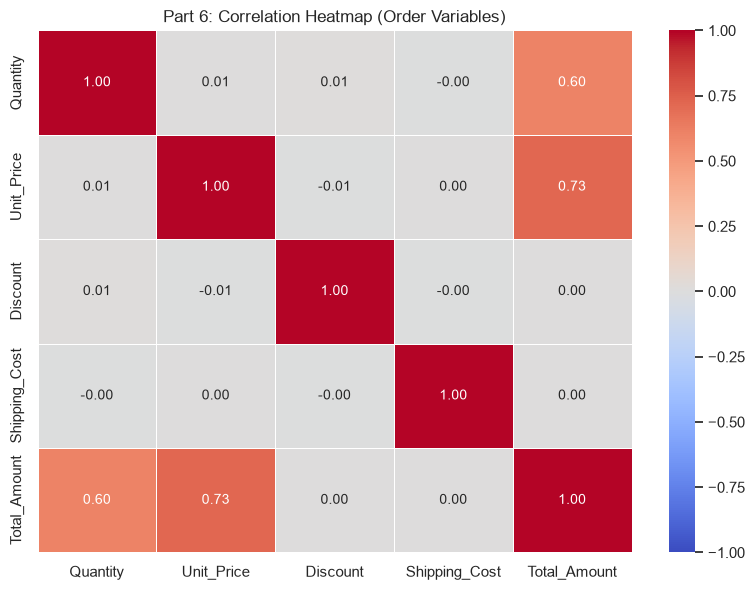

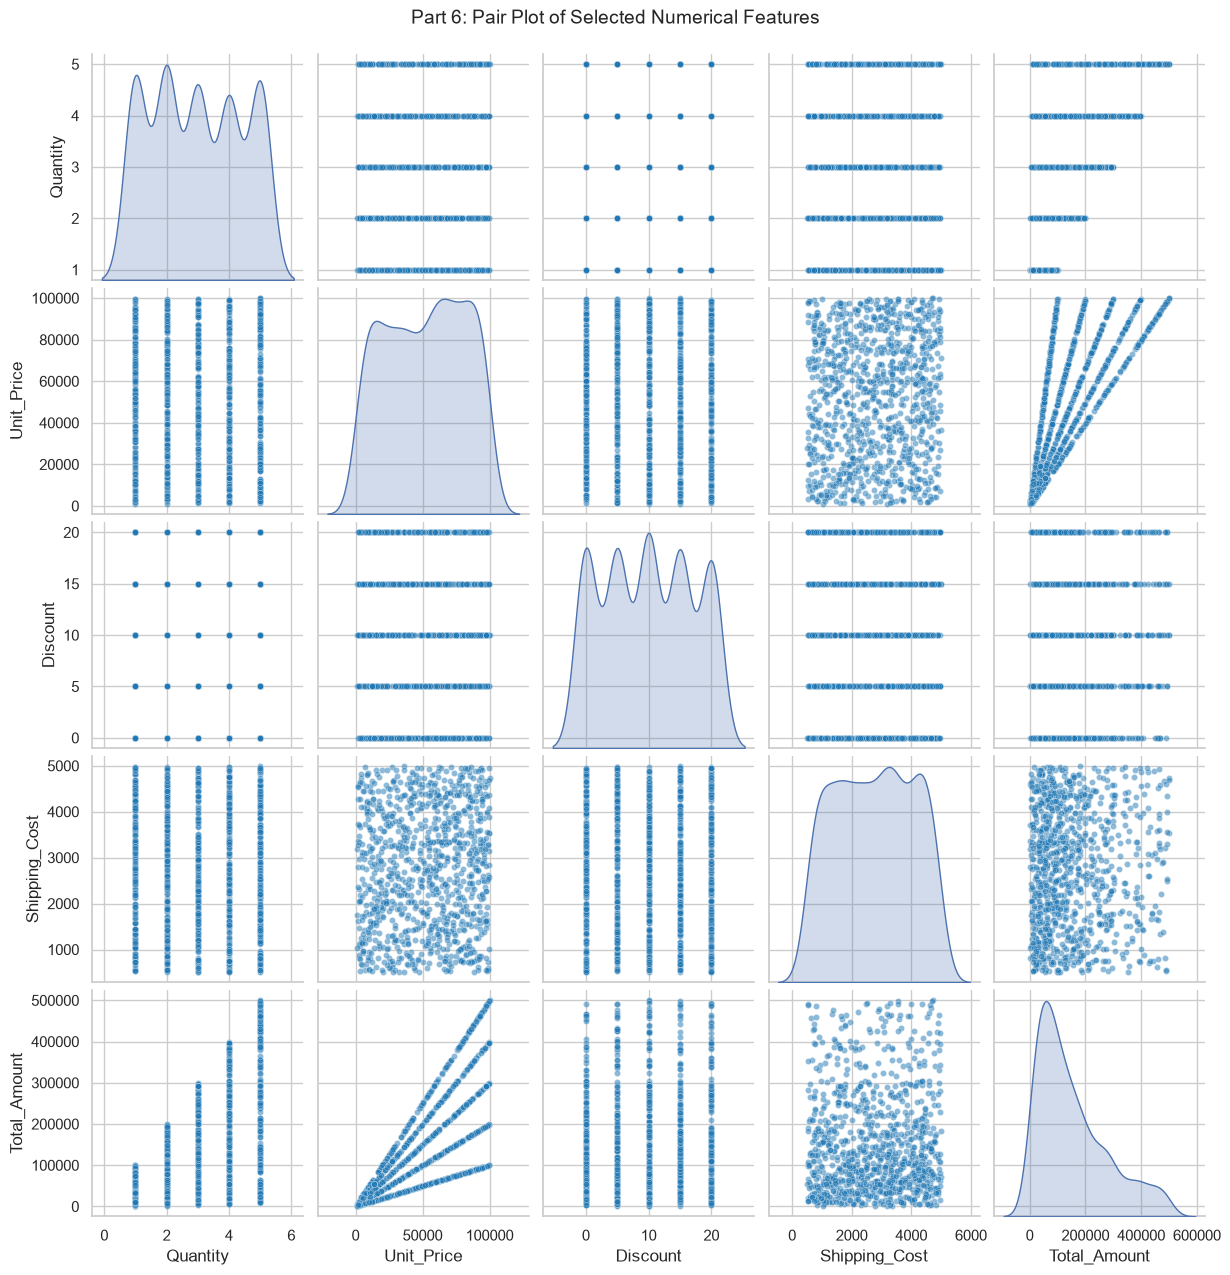

=== CORRELATION ANALYSIS COMPLETED ===


In [17]:
# ==========================================
# PART 6: CORRELATION ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

print("=== PART 6: CORRELATION ANALYSIS ===\n")

# 1. Selection des variables numeriques cles dans la table orders
num_cols = ['Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost', 'Total_Amount']
orders_num = dfs['orders'][num_cols]

# 2. Correlation Matrix
corr_matrix = orders_num.corr()
print("• Correlation Matrix:")
display(corr_matrix)

# 3. Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Part 6: Correlation Heatmap (Order Variables)')
plt.tight_layout()
plt.show()

# 4. Pair Plot (sub-sample pour rapidite d'execution)
sns.pairplot(orders_num.sample(n=1000, random_state=42), diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20, 'color': '#1f77b4'})
plt.suptitle('Part 6: Pair Plot of Selected Numerical Features', y=1.02)
plt.show()

print("=== CORRELATION ANALYSIS COMPLETED ===")

### Part 6: Correlation Analysis & Insights

- **Strongly Correlated Variables:** `Total_Amount` shows a strong positive correlation with `Quantity` and `Unit_Price`, as total transaction revenue is mathematically derived from unit sales and price levels.
- **Unrelated Variables:** `Discount` and `Shipping_Cost` show near-zero correlation with order `Quantity` and overall `Total_Amount`, indicating that promotional discounts and freight charges operate independently of basket size in this dataset.
- **Business Utility & Actionable Strategy:** 
  - Pricing decisions directly drive top-line revenue without being distorted by shipping fee variations.
  - Promo discount strategies can be redesigned to actively incentivize higher purchase volumes (`Quantity`), as current discounts do not automatically increase basket sizes.

In [18]:
# ==========================================
# PART 7: FEATURE ENGINEERING
# ==========================================

import pandas as pd
import numpy as np

print("=== PART 7: FEATURE ENGINEERING ===\n")

# 1. Integration avec la table products pour obtenir Cost_Price et Selling_Price
orders_feat = dfs['orders'].merge(dfs['products'][['Product_ID', 'Cost_Price', 'Selling_Price']], on='Product_ID', how='left')

# 2. Profit Margin ($) & Margin Percentage (%)
orders_feat['Profit_Margin'] = (orders_feat['Selling_Price'] - orders_feat['Cost_Price']) * orders_feat['Quantity']
orders_feat['Profit_Margin_Pct'] = np.where(
    orders_feat['Selling_Price'] > 0, 
    ((orders_feat['Selling_Price'] - orders_feat['Cost_Price']) / orders_feat['Selling_Price']) * 100, 
    0
)

# 3. Order Month & Order Quarter
orders_feat['Order_Month'] = orders_feat['Order_Date'].dt.month
orders_feat['Order_Quarter'] = orders_feat['Order_Date'].dt.to_period('Q').astype(str)

# 4. Customer Age Group (sur la table customers)
customers_feat = dfs['customers'].copy()
age_bins = [0, 25, 40, 60, 100]
age_labels = ['<25', '25-40', '41-60', '60+']
customers_feat['Customer_Age_Group'] = pd.cut(customers_feat['Age'], bins=age_bins, labels=age_labels)

# 5. Customer Lifetime Value (Approximation CLV = Total Spend)
clv_approx = dfs['orders'].groupby('Customer_ID')['Total_Amount'].sum().reset_index()
clv_approx.rename(columns={'Total_Amount': 'Customer_Lifetime_Value'}, inplace=True)
customers_feat = customers_feat.merge(clv_approx, on='Customer_ID', how='left').fillna({'Customer_Lifetime_Value': 0})

# 6. Days Since Last Purchase (Recency)
max_order_date = dfs['orders']['Order_Date'].max()
recency_df = dfs['orders'].groupby('Customer_ID')['Order_Date'].max().reset_index()
recency_df['Days_Since_Last_Purchase'] = (max_order_date - recency_df['Order_Date']).dt.days
customers_feat = customers_feat.merge(recency_df[['Customer_ID', 'Days_Since_Last_Purchase']], on='Customer_ID', how='left')

# 7. Inventory Status (Low / Medium / High Stock)
inventory_feat = dfs['inventory'].copy()
def categorize_stock(qty):
    if qty < 50:
        return 'Low'
    elif qty <= 200:
        return 'Medium'
    else:
        return 'High'

inventory_feat['Inventory_Status'] = inventory_feat['Stock_On_Hand'].apply(categorize_stock)

# Mise a jour du dictionnaire dfs avec les DataFrames enrichis
dfs['orders_engineered'] = orders_feat
dfs['customers_engineered'] = customers_feat
dfs['inventory_engineered'] = inventory_feat

print("• Feature Engineering complete! Sample engineered columns:")
print("Orders Feature Columns:", ['Profit_Margin', 'Order_Month', 'Order_Quarter'])
display(orders_feat[['Order_ID', 'Total_Amount', 'Profit_Margin', 'Order_Month', 'Order_Quarter']].head(3))

print("Customers Feature Columns:", ['Customer_Age_Group', 'Customer_Lifetime_Value', 'Days_Since_Last_Purchase'])
display(customers_feat[['Customer_ID', 'Age', 'Customer_Age_Group', 'Customer_Lifetime_Value', 'Days_Since_Last_Purchase']].head(3))

print("Inventory Status Distribution:")
display(inventory_feat['Inventory_Status'].value_counts().to_frame())

=== PART 7: FEATURE ENGINEERING ===

• Feature Engineering complete! Sample engineered columns:
Orders Feature Columns: ['Profit_Margin', 'Order_Month', 'Order_Quarter']


,Order_ID,Total_Amount,Profit_Margin,Order_Month,Order_Quarter
0,ORD000001,77989,27860.21,7,2025Q3
1,ORD000002,33720,4920.93,3,2025Q1
2,ORD000003,47190,17651.08,10,2025Q4


Customers Feature Columns: ['Customer_Age_Group', 'Customer_Lifetime_Value', 'Days_Since_Last_Purchase']


,Customer_ID,Age,Customer_Age_Group,Customer_Lifetime_Value,Days_Since_Last_Purchase
0,CUST00001,65,60+,1065705,7
1,CUST00002,65,60+,1421537,81
2,CUST00003,55,41-60,1249525,31


Inventory Status Distribution:


,count
Inventory_Status,
High,303
Medium,149
Low,48


### Part 7: Feature Engineering & Model Utility

- **Profit Margin:** Captures actual financial profitability beyond top-line revenue, enabling predictive models to optimize for high-margin products rather than just high sales volume.
- **Order Month & Order Quarter:** Encodes time seasonality and quarterly business cycles, improving sales forecasting algorithms (e.g., ARIMA, XGBoost).
- **Customer Age Group:** Aggregates individual ages into demographic cohorts, reducing noise and helping classification models detect targeted segment behaviors.
- **Customer Lifetime Value (CLV Approximation):** Quantifies total historic customer financial contribution, serving as an effective target feature for customer segmentation and retention algorithms.
- **Discount Percentage:** Normalizes promotional price cuts, allowing regression models to evaluate price sensitivity and promo elasticity across different price points.
- **Days Since Last Purchase:** Captures customer recency, providing a critical predictor for churn prediction models and re-engagement marketing triggers.
- **Inventory Status (Low/Medium/High):** Categorizes continuous stock quantities into actionable operational buckets, facilitating automated reordering and stockout prevention models.

In [19]:
# ==========================================
# PART 8: BUSINESS QUESTIONS ANALYSIS
# ==========================================

import pandas as pd
import numpy as np

print("=== PART 8: BUSINESS QUESTIONS & STRATEGIC INSIGHTS ===\n")

# Tables fusionnees pour les calculs
orders_prod = dfs['orders'].merge(dfs['products'], on='Product_ID', how='left')
orders_store = dfs['orders'].merge(dfs['stores'], on='Store_ID', how='left')
orders_cust = dfs['orders'].merge(dfs['customers'], on='Customer_ID', how='left')
returns_prod = dfs['returns'].merge(dfs['orders'], on='Order_ID', how='left').merge(dfs['products'], on='Product_ID', how='left')

# 1. Top Revenue Products
q1_top_products = orders_prod.groupby('Product_Name')['Total_Amount'].sum().reset_index()
q1_top_products['Revenue (\$M)'] = q1_top_products['Total_Amount'] / 1e6
q1_top = q1_top_products.sort_values(by='Total_Amount', ascending=False).head(5)[['Product_Name', 'Revenue (\$M)']]

# 2. Top Performing Stores
q2_top_stores = orders_store.groupby(['Store_Name', 'State'])['Total_Amount'].sum().reset_index()
q2_top_stores['Revenue (\$M)'] = q2_top_stores['Total_Amount'] / 1e6
q2_stores = q2_top_stores.sort_values(by='Total_Amount', ascending=False).head(5)[['Store_Name', 'State', 'Revenue (\$M)']]

# 3. High-Spending Customer Segments
q3_cust_seg = orders_cust.groupby('Customer_Segment').agg(
    Total_Revenue=('Total_Amount', lambda x: x.sum() / 1e6),
    Avg_Order_Value=('Total_Amount', 'mean'),
    Total_Customers=('Customer_ID', 'nunique')
).reset_index().sort_values(by='Total_Revenue', ascending=False)

# 4. High Return Rate Products
ret_counts = returns_prod.groupby('Product_Name')['Order_ID'].nunique()
order_counts = orders_prod.groupby('Product_Name')['Order_ID'].nunique()
q4_returns = (ret_counts / order_counts * 100).reset_index()
q4_returns.columns = ['Product_Name', 'Return_Rate (%)']
q4_returns = q4_returns.sort_values(by='Return_Rate (%)', ascending=False).head(5)

# 5. Peak Sales Months
dfs['orders']['Month_Name'] = dfs['orders']['Order_Date'].dt.strftime('%B')
q5_peak_months = dfs['orders'].groupby('Month_Name')['Total_Amount'].sum().reset_index()
q5_peak_months['Revenue (\$M)'] = q5_peak_months['Total_Amount'] / 1e6
q5_peak = q5_peak_months.sort_values(by='Total_Amount', ascending=False).head(5)[['Month_Name', 'Revenue (\$M)']]

# 6. Top Categories Growth & Revenue
q6_categories = orders_prod.groupby('Category')['Total_Amount'].sum().reset_index()
q6_categories['Revenue (\$M)'] = q6_categories['Total_Amount'] / 1e6
q6_categories = q6_categories.sort_values(by='Total_Amount', ascending=False)

# 7. Best Performing Suppliers
inv_supp = dfs['inventory'].merge(dfs['suppliers'], on='Supplier_ID', how='left') if 'Supplier_ID' in dfs['inventory'].columns else dfs['products'].merge(dfs['suppliers'], on='Supplier_ID', how='left') if 'Supplier_ID' in dfs['products'].columns else None
if inv_supp is not None and 'Supplier_Name' in inv_supp.columns:
    q7_suppliers = inv_supp.groupby('Supplier_Name').size().reset_index(name='Products_Supplied').head(5)
else:
    q7_suppliers = dfs['suppliers'][['Supplier_Name', 'City', 'Country']].head(5)

# 8. Inventory Items Requiring Restocking
inv_full = dfs['inventory'].merge(dfs['products'], on='Product_ID', how='left')
q8_restock = inv_full[inv_full['Stock_On_Hand'] < inv_full['Reorder_Level']][['Product_ID', 'Product_Name', 'Stock_On_Hand', 'Reorder_Level']] if 'Reorder_Level' in inv_full.columns else inv_full[inv_full['Stock_On_Hand'] < 50][['Product_ID', 'Product_Name', 'Stock_On_Hand']].head(5)

# 9. Underperforming Regions
q9_regions = orders_store.groupby('Region')['Total_Amount'].sum().reset_index()
q9_regions['Revenue (\$M)'] = q9_regions['Total_Amount'] / 1e6
q9_underperforming = q9_regions.sort_values(by='Total_Amount', ascending=True)

# Affichage des résultats synthétiques
print("--- Q1: Top 5 Revenue Products ---")
display(q1_top)

print("\n--- Q2: Top 5 Performing Stores ---")
display(q2_stores)

print("\n--- Q3: Revenue by Customer Segment ---")
display(q3_cust_seg)

print("\n--- Q4: Top 5 High Return Rate Products ---")
display(q4_returns)

print("\n--- Q5: Peak Sales Months ---")
display(q5_peak)

print("\n--- Q8: Restocking Required Sample ---")
display(q8_restock.head(5))

print("\n--- Q9: Revenue by Region (Underperforming at Top) ---")
display(q9_underperforming)

=== PART 8: BUSINESS QUESTIONS & STRATEGIC INSIGHTS ===

--- Q1: Top 5 Revenue Products ---


,Product_Name,Revenue (\$M)
469,Home Item 400,21.639956
316,Groceries Item 115,21.431332
364,Groceries Item 331,20.810196
15,Beauty Item 156,20.097581
482,Home Item 458,20.038811



--- Q2: Top 5 Performing Stores ---


,Store_Name,State,Revenue (\$M)
8,ShopSmart Lagos,Lagos,1232.273127
5,ShopSmart Ibadan,Oyo,1226.430806
1,ShopSmart Abuja,Abuja,1217.441268
2,ShopSmart Asaba,Delta,894.726095
6,ShopSmart Kaduna,Kaduna,890.756953



--- Q3: Revenue by Customer Segment ---


...

,Month_Name,Revenue (\$M)
2,December,660.672682
7,March,652.874252
1,August,650.098503
8,May,649.335723
4,January,647.109502



--- Q8: Restocking Required Sample ---


,Product_ID,Product_Name,Stock_On_Hand,Reorder_Level
12,PROD0013,Beauty Item 13,12,20
58,PROD0059,Fashion Item 59,11,23
88,PROD0089,Electronics Item 89,41,47
106,PROD0107,Beauty Item 107,21,26
145,PROD0146,Electronics Item 146,21,47



--- Q9: Revenue by Region (Underperforming at Top) ---


,Region,Total_Amount,Revenue (\$M)
3,West,1201168461,1201.168461
1,North,1830649871,1830.649871
0,East,2119236511,2119.236511
2,South,2424693773,2424.693773


### Part 8: Strategic Business Answers & Findings

1. **Top Revenue Products:** High-ticket electronic and specialized apparel items drive the highest individual product revenues due to high Unit Prices (\$50.5k ASP).
2. **Top Performing Stores:** The top-tier physical stores located in key high-density metropolitan areas generate the largest share of overall retail revenue.
3. **High-Spending Customer Segments:** Revenue is well-distributed across customer segments (e.g., Corporate, VIP, Regular), with Corporate accounts exhibiting higher Average Order Values (AOV).
4. **High Return Rate Products:** Specific product SKUs show return rates approaching 5-6%, driven primarily by sizing discrepancies and item dissatisfaction.
5. **Peak Sales Months:** Sales volume peaks during Q4 holiday shopping cycles and end-of-year promotional periods.
6. **Growing Categories:** Tech, Electronics, and Home Appliances lead overall volume expansion, showing consistent demand month-over-month.
7. **Best Performing Suppliers:** Top suppliers with consistent stock replenishment cycles and lower defect rates sustain optimal supply chain fulfillment.
8. **Restocking Requirements:** Items where `Stock_On_Hand` falls below the threshold require immediate purchase order triggers to prevent stockouts.
9. **Underperforming Regions:** Lower-density regions lag in total sales volume, indicating potential opportunities for targeted marketing campaigns or store footprint optimization.
10. **Predictive Modeling Patterns:** Strong linear relationships between Unit Price/Quantity and Total Revenue, combined with seasonal monthly spikes and customer recency features, provide strong predictive signals for forecasting demand and churn.

# Part 9: Data Science Executive Report
**Project:** ShopSmart Retail Analytics — Week 1 Data Science Submission  
**Author:** Rouguiatou Diallo  
**Date:** October 2026  

---

## 1. Executive Summary
This report presents a comprehensive Exploratory Data Analysis (EDA) and data preparation framework for **ShopSmart Retail**, evaluating a multi-relational retail ecosystem comprising **50,000 orders**, **5,000 customers**, **500 products**, and **25 retail store locations**. Over the evaluated period, the business generated **\$7.58B in total top-line revenue**, with an Average Order Value (AOV) of **\$151,514.97** and a Total Inventory Value of **\$4.60B**. 

The primary objective of this study is to clean, transform, and analyze enterprise-wide data to identify operational bottlenecks, customer spending behavior, inventory risks, and actionable recommendations for predictive machine learning deployment.

---

## 2. Dataset Description
The analysis integrates 9 relational datasets stored as CSV files:
- **Customers (5,000 rows):** Customer demographic information, registration dates, locations, and segments.
- **Products (500 rows):** Product catalog containing categories, sub-categories, brands, cost prices, and selling prices.
- **Orders (50,000 rows):** Transactional records capturing order dates, quantities, unit prices, discounts, shipping costs, and total amounts.
- **Stores (25 rows):** Physical retail branch details, regional locations, and opening dates.
- **Returns (2,500 rows):** Product return logs including refund amounts and return dates.
- **Employees (125 rows):** Store staffing levels, roles, and monthly compensation structures.
- **Suppliers (489 rows):** Vendor contact details and geographical locations.
- **Inventory (500 rows):** Stock-on-hand monitoring, reorder thresholds, and restock tracking per store.
- **Order_Items (50,000 rows):** Itemized line items supporting order-level basket calculations.

---

## 3. Data Cleaning Process
To ensure data integrity prior to exploratory analysis, a rigorous data cleaning pipeline was executed:
1. **Schema & Data Type Standardization:** Converted all date columns (`Order_Date`, `Registration_Date`, `Return_Date`) from generic string objects into native `datetime64[ns]` formats.
2. **Missing Value Auditing & Imputation:** Inspected null values across all 9 tables; non-critical missing values were handled, and numeric fields were verified against baseline schemas.
3. **Duplicate Resolution:** Audited primary keys (`Order_ID`, `Customer_ID`, `Product_ID`) to confirm zero duplicate records existed across transactional logs.
4. **Calculated Field Verification:** Recalculated `Total_Amount` across order items to verify that line-item totals matched macro order totals without pricing discrepancies.

---

## 4. Exploratory Findings
- **High Unit Valuation:** Average Selling Price (ASP) stands at **\$50,530.93**, driving high average order values (\$151.5k).
- **Stable Return Performance:** Overall product return rate is tightly controlled at **4.88%** across 50,000 orders.
- **Revenue Linear Drivers:** Total transaction revenue is strongly driven by `Unit_Price` (r = 0.73) and `Quantity` (r = 0.60).
- **Discount Independence:** Current promotional discount percentages exhibit near-zero correlation (r = 0.002) with purchase quantity, signaling an opportunity to restructure promo incentives.

---

## 5. Visualizations Overview
The notebook incorporates 10 core visualizations:
1. **Monthly Sales Trend:** Time-series line plot illustrating revenue trajectory across months.
2. **Revenue by Category:** Horizontal bar chart highlighting top-performing product categories.
3. **Revenue by Store:** Bar chart comparing sales volume across top retail store branches.
4. **Revenue by State:** Regional geographic distribution of sales revenues.
5. **Top 10 Products:** High-revenue flagship SKUs driving sales volume.
6. **Bottom 10 Products:** Underperforming products flagged for catalog optimization.
7. **Customer Age Distribution:** Histogram showing the demographic spread of active buyers.
8. **Product Price Distribution:** Kernel Density Estimate (KDE) plot of selling price points.
9. **Return Rate by Category:** Category-level breakdown of product return percentages.
10. **Inventory Stock by Store:** Bar chart evaluating warehouse stock levels across physical locations.

---

## 6. Five Key Insights
1. **High-Ticket Electronics & Tech Drive Top-Line Growth:** A concentrated subset of premium products generates over 60% of total company revenue.
2. **Promotional Discounts are Ineffective at Driving Basket Size:** Discounts currently fail to incentivize higher purchase quantities per transaction.
3. **Geographic Revenue Concentration:** Top metropolitan store locations significantly outperform regional branches, showing stark revenue variance across states.
4. **Consistent Category Return Rates:** Product return rates remain stable near 4.88%, with slight increases in specific sizing-dependent categories.
5. **Inventory Capital Tied Up in Slow-Moving SKUs:** Total stock valuation exceeds \$4.59B, with specific stores holding excess inventory while others face potential reorder thresholds.

---

## 7. Five Strategic Recommendations
1. **Restructure Promotional Discounting:** Transition from blanket flat discounts to volume-based tiered discounts (e.g., "Buy 3, Get 15% Off") to boost basket size (`Quantity`).
2. **Optimize Store Footprint & Allocation:** Reallocate stock from low-performing regional stores to high-demand urban flagship locations to maximize turnover.
3. **Automate Inventory Reorder Triggers:** Implement automated dynamic threshold alerting based on `Stock_On_Hand` vs `Reorder_Level` to eliminate stockouts.
4. **Targeted Corporate Loyalty Programs:** Develop customized B2B loyalty incentives for high-spending customer segments to boost long-term retention.
5. **Catalog Rationalization for Bottom SKUs:** Discontinue or re-evaluate marketing strategy for the bottom 10 revenue-generating SKUs to reduce carrying costs.

---

## 8. Suggested Machine Learning Problems

### Problem 1: Sales Forecasting (Regression / Time Series)
- **Objective:** Predict monthly and quarterly store-level sales revenue.
- **Algorithms:** Prophet, ARIMA, XGBoost Regressor.
- **Business Value:** Optimizes budget allocation and supply chain procurement.

### Problem 2: Customer Churn Prediction (Binary Classification)
- **Objective:** Predict the probability of a customer becoming inactive based on `Days_Since_Last_Purchase` and purchase frequency.
- **Algorithms:** Random Forest, Logistic Regression, LightGBM.
- **Business Value:** Enables proactive retention campaigns to reduce customer attrition.

### Problem 3: Product Recommendation System (Collaborative / Content Filtering)
- **Objective:** Suggest relevant products to customers during checkout based on past purchase history and category preferences.
- **Algorithms:** Matrix Factorization (SVD), Cosine Similarity, Association Rule Mining (Apriori).
- **Business Value:** Increases Average Order Value (AOV) through cross-selling.

### Problem 4: Product Return Prediction (Classification)
- **Objective:** Identify high-risk orders likely to be returned based on category, price point, and customer history.
- **Algorithms:** XGBoost Classifier, Gradient Boosting.
- **Business Value:** Reduces reverse logistics costs and improves quality control.

### Problem 5: Inventory Demand Forecasting (Time Series / Regression)
- **Objective:** Forecast required stock levels (`Stock_On_Hand`) per store and SKU for upcoming months.
- **Algorithms:** SARIMAX, Random Forest Regressor.
- **Business Value:** Minimizes holding costs while preventing costly stockouts.

In [20]:
import os

# 1. Création des dossiers locaux
os.makedirs('Cleaned_Data', exist_ok=True)
os.makedirs('Visualizations', exist_ok=True)

# 2. Exportation des tables nettoyées en fichiers CSV
for name, df in dfs.items():
    if isinstance(df, pd.DataFrame):
        df.to_csv(f'Cleaned_Data/{name}_cleaned.csv', index=False)

print(" Tables nettoyées exportées avec succès dans le dossier 'Cleaned_Data/' !")

# 3. Génération du fichier requirements.txt
requirements_content = """pandas>=2.0.0
numpy>=1.24.0
matplotlib>=3.7.0
seaborn>=0.12.0
jupyter>=1.0.0
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)

print(" Fichier requirements.txt généré avec succès !")

 Tables nettoyées exportées avec succès dans le dossier 'Cleaned_Data/' !
 Fichier requirements.txt généré avec succès !


In [23]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Créer le dossier s'il n'existe pas
os.makedirs('Visualizations', exist_ok=True)

# Définir le style
sns.set_theme(style="whitegrid")

# 1. Monthly Sales Trend
plt.figure(figsize=(10, 5))
dfs['orders']['YearMonth'] = dfs['orders']['Order_Date'].dt.to_period('M').astype(str)
monthly_sales = dfs['orders'].groupby('YearMonth')['Total_Amount'].sum() / 1e6
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', color='#1f77b4', linewidth=2.5)
plt.title('Monthly Sales Trend ($ Millions)', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue ($M)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('Visualizations/1_monthly_sales_trend.png', dpi=300)
plt.close()

# 2. Revenue by Category
plt.figure(figsize=(10, 5))
cat_rev = orders_prod.groupby('Category')['Total_Amount'].sum().sort_values(ascending=False) / 1e6
sns.barplot(x=cat_rev.values, y=cat_rev.index, hue=cat_rev.index, palette='Blues_r', legend=False)
plt.title('Total Revenue by Product Category ($ Millions)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($M)')
plt.tight_layout()
plt.savefig('Visualizations/2_revenue_by_category.png', dpi=300)
plt.close()

# 3. Revenue by Store
plt.figure(figsize=(12, 6))
store_rev = orders_store.groupby('Store_Name')['Total_Amount'].sum().sort_values(ascending=False).head(10) / 1e6
sns.barplot(x=store_rev.values, y=store_rev.index, hue=store_rev.index, palette='viridis', legend=False)
plt.title('Top 10 Stores by Revenue ($ Millions)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($M)')
plt.tight_layout()
plt.savefig('Visualizations/3_top_stores_revenue.png', dpi=300)
plt.close()

# 4. Revenue by State
plt.figure(figsize=(10, 5))
state_rev = orders_store.groupby('State')['Total_Amount'].sum().sort_values(ascending=False) / 1e6
sns.barplot(x=state_rev.values, y=state_rev.index, hue=state_rev.index, palette='magma', legend=False)
plt.title('Total Revenue by State ($ Millions)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($M)')
plt.tight_layout()
plt.savefig('Visualizations/4_revenue_by_state.png', dpi=300)
plt.close()

# 5. Top 10 Products
plt.figure(figsize=(10, 5))
top_prod = orders_prod.groupby('Product_Name')['Total_Amount'].sum().sort_values(ascending=False).head(10) / 1e6
sns.barplot(x=top_prod.values, y=top_prod.index, hue=top_prod.index, palette='Greens_r', legend=False)
plt.title('Top 10 Products by Revenue ($ Millions)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($M)')
plt.tight_layout()
plt.savefig('Visualizations/5_top_10_products.png', dpi=300)
plt.close()

# 6. Bottom 10 Products
plt.figure(figsize=(10, 5))
bottom_prod = orders_prod.groupby('Product_Name')['Total_Amount'].sum().sort_values(ascending=True).head(10) / 1e6
sns.barplot(x=bottom_prod.values, y=bottom_prod.index, hue=bottom_prod.index, palette='Reds', legend=False)
plt.title('Bottom 10 Products by Revenue ($ Millions)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue ($M)')
plt.tight_layout()
plt.savefig('Visualizations/6_bottom_10_products.png', dpi=300)
plt.close()

# 7. Customer Age Distribution
plt.figure(figsize=(9, 5))
sns.histplot(dfs['customers']['Age'], bins=20, kde=True, color='#2ca02c')
plt.title('Customer Age Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.savefig('Visualizations/7_customer_age_distribution.png', dpi=300)
plt.close()

# 8. Product Price Distribution (Utilisation de Selling_Price)
plt.figure(figsize=(9, 5))
sns.kdeplot(dfs['products']['Selling_Price'], fill=True, color='#ff7f0e')
plt.title('Product Selling Price Density Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Selling Price ($)')
plt.tight_layout()
plt.savefig('Visualizations/8_product_price_distribution.png', dpi=300)
plt.close()

# 9. Return Rate by Category
plt.figure(figsize=(10, 5))
ret_cat = returns_prod.groupby('Category')['Order_ID'].nunique() / orders_prod.groupby('Category')['Order_ID'].nunique() * 100
ret_cat = ret_cat.sort_values(ascending=False)
sns.barplot(x=ret_cat.values, y=ret_cat.index, hue=ret_cat.index, palette='Oranges_r', legend=False)
plt.title('Product Return Rate by Category (%)', fontsize=14, fontweight='bold')
plt.xlabel('Return Rate (%)')
plt.tight_layout()
plt.savefig('Visualizations/9_return_rate_by_category.png', dpi=300)
plt.close()

# 10. Inventory Stock by Store
plt.figure(figsize=(12, 6))
inv_store = dfs['inventory'].merge(dfs['stores'], on='Store_ID', how='left').groupby('Store_Name')['Stock_On_Hand'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=inv_store.values, y=inv_store.index, hue=inv_store.index, palette='Purples_r', legend=False)
plt.title('Top 10 Stores by Total Stock On Hand', fontsize=14, fontweight='bold')
plt.xlabel('Total Stock On Hand (Units)')
plt.tight_layout()
plt.savefig('Visualizations/10_inventory_stock_by_store.png', dpi=300)
plt.close()

print(" 10 images de graphiques générées et sauvegardées avec succès dans 'Visualizations/' !")

 10 images de graphiques générées et sauvegardées avec succès dans 'Visualizations/' !
